In [1]:
from II_funcs import *
import corner
import re
plt.rcParams['mathtext.fontset'] =  "cm"
plt.rcParams['font.family'] =  "serif"
plt.rcParams['mathtext.default']='regular'

from IPython.display import FileLink
import gc
from scipy.interpolate import RectBivariateSpline
gc.collect()
theta_E_4 = np.array([np.sqrt(4 * G * .4*(2e33) / c**2 * D_ls / (D_s * D_l))])
theta_E_8 = np.array([np.sqrt(4 * G * .8*(2e33) / c**2 * D_ls / (D_s * D_l))])

data=np.load('macro_lens_results.npz')
mag_fit=6.86
phi_0=-2.07858699980682
B_matrix=data['inv_jacobian_fit'][0]
from scipy.interpolate import RegularGridInterpolator
from scipy.stats import linregress


D_s = 4.603e+27 cm
D_l = 3.085e+27 cm
D_ls = 3.708e+27 cm


In [2]:
#define image specific constants, these don't change within this file
theta_max = 2e-10 # (half) size of image
image_size=8000
N_step = image_size
beta_min = .9e-11
rad = theta_500  
rad_mas=rad*rad_to_arcsec
g_params = (kappa_bulk, gamma1, gamma2)
sigma_C = error_C(mag=16.5, wavelength=500*1e-7, R = 2e4, sigma_t=3e-12, A=10*(500**2)*np.pi, t_obs= 8 * 3600)

In [3]:
def rotate_data_pos(xpts, ypts, theta):
    "xpts, ypts are relative to 0 0 in the right bottom corner of the image. theta in radians"
    xpts=np.array(xpts)
    ypts=np.array(ypts)
    xpts=xpts-0.5
    ypts=ypts-0.5
    rs=np.sqrt(xpts**2+ypts**2)
    x2=rs*np.cos(np.arctan2(xpts, ypts)+theta)
    y2=rs*np.sin(np.arctan2(xpts, ypts)+theta)
    return x2, y2

def load_file(file, skip_lines=0, matrix=True, force_shape=(4,4)):
    """
    Parse file with entries where each entry has a header (5 or 6 numeric tokens)
    followed by a matrix block between [[ and ]].
    Returns:
      out_xval: (N,2) array (second column nan if header had single x)
      out_rad, out_mass, out_x, out_y: 1D arrays length N
      out_mat: list of numpy arrays (each either reshaped to force_shape if possible, else 1D)
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)

    out_x1, out_x2 = [], []
    out_rad, out_mass, out_x, out_y = [], [], [], []
    out_mat = []

    # find all matrix blocks; iterate in order and take header as text since previous end
    prev_end = 0
    for m in re.finditer(r'\[\[.*?\]\]', raw, flags=re.S):
        header_text = raw[prev_end:m.start()].strip()
        matrix_text = m.group()
        prev_end = m.end()

        # extract numeric-ish tokens from header (includes 'nan')
        header_tokens = token_re.findall(header_text)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")

        # convert tokens to floats, treating 'nan' correctly
        def tok_to_float(t):
            return np.nan if t.lower() == 'nan' else float(t)
        header_vals = [tok_to_float(t) for t in header_tokens]

        # map header tokens -> fields (6-token or 5-token)
        if len(header_vals) == 6:
            x1, x2, rad, mass, xpos, ypos = header_vals
        elif len(header_vals) == 5:
            x1, x2 = header_vals[0], np.nan
            rad, mass, xpos, ypos = header_vals[1], header_vals[2], header_vals[3], header_vals[4]
        else:
            raise ValueError(
                f"Unexpected number of header tokens ({len(header_vals)}) found: {header_tokens!r}\n"
                "Expected 5 or 6 tokens."
            )

        out_x1.append(x1)
        out_x2.append(x2)
        out_rad.append(rad)
        out_mass.append(mass)
        out_x.append(xpos)
        out_y.append(ypos)

        if matrix:
            mat_tokens = token_re.findall(matrix_text)
            if not mat_tokens:
                mat_arr = np.array([], dtype=float)
            else:
                mat_vals = [tok_to_float(t) for t in mat_tokens]
                mat_arr = np.array(mat_vals, dtype=float)
                # reshape if shape matches force_shape
                if force_shape is not None and mat_arr.size == np.prod(force_shape):
                    mat_arr = mat_arr.reshape(force_shape)
            out_mat.append(mat_arr)

    # if there was trailing text after last matrix containing another valid entry without matrix,
    # it won't be processed. That's intentional: function associates matrices with preceding headers.

    out_xval = np.column_stack([np.array(out_x1, dtype=float), np.array(out_x2, dtype=float)])
    return (out_xval,
            np.array(out_rad, dtype=float),
            np.array(out_mass, dtype=float),
            np.array(out_x, dtype=float),
            np.array(out_y, dtype=float),
            out_mat if matrix else None)
    
def load_mag_file(file, skip_lines=0, matrix=True, force_shape=(4,4)):
    """
    Parse file with entries where each entry has a header (5 or 6 numeric tokens)
    followed by a matrix block between [[ and ]].
    Returns:
      out_xval: (N,2) array (second column nan if header had single x)
      out_rad, out_mass, out_x, out_y: 1D arrays length N
      out_mat: list of numpy arrays (each either reshaped to force_shape if possible, else 1D)
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)

    out_x1, out_x2 = [], []
    out_mat = []

    # find all matrix blocks; iterate in order and take header as text since previous end
    prev_end = 0
    for m in re.finditer(r'\[\[.*?\]\]', raw, flags=re.S):
        header_text = raw[prev_end:m.start()].strip()
        matrix_text = m.group()
        prev_end = m.end()

        # extract numeric-ish tokens from header (includes 'nan')
        header_tokens = token_re.findall(header_text)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")

        # convert tokens to floats, treating 'nan' correctly
        def tok_to_float(t):
            return np.nan if t.lower() == 'nan' else float(t)
        header_vals = [tok_to_float(t) for t in header_tokens]

        # map header tokens -> fields (6-token or 5-token)
        if len(header_vals) == 2:
            x1, x2 = header_vals
        if len(header_vals) == 1:
            x1 = header_vals
            x2=0
        #elif len(header_vals) == 5:
        #    x1, x2 = header_vals[0], np.nan
        #    rad, mass, xpos, ypos = header_vals[1], header_vals[2], header_vals[3], header_vals[4]
        #else:
        #    raise ValueError(
        #        f"Unexpected number of header tokens ({len(header_vals)}) found: {header_tokens!r}\n"
        #        "Expected 5 or 6 tokens."
        #    )

        out_x1.append(x1)
        out_x2.append(x2)

        if matrix:
            mat_tokens = token_re.findall(matrix_text)
            if not mat_tokens:
                mat_arr = np.array([], dtype=float)
            else:
                mat_vals = [tok_to_float(t) for t in mat_tokens]
                mat_arr = np.array(mat_vals, dtype=float)
                # reshape if shape matches force_shape
                if force_shape is not None and mat_arr.size == np.prod(force_shape):
                    mat_arr = mat_arr.reshape(force_shape)
            out_mat.append(mat_arr)

    # if there was trailing text after last matrix containing another valid entry without matrix,
    # it won't be processed. That's intentional: function associates matrices with preceding headers.
    if np.array(out_x2).any!=0:
        out_xval = np.column_stack([np.array(out_x1, dtype=float), np.array(out_x2, dtype=float)])
    else:
        out_xval = np.column_stack([np.array(out_x1, dtype=float)])
    return (out_xval,
            out_mat if matrix else None)

def load_cents(file):
    centroids=[]
    positions=[]
    with open(file, 'r') as fh:
        lines = fh.readlines()[:]
        for i in range(len(lines)):
            
            positions.append(np.array((float(lines[i].split(']')[0].split('[')[1].split(' ')[0]), 
                                       float(lines[i].split(']')[0].split('[')[1].split(' ')[1]))))
            J0=(np.array((float((lines[i].split(']')[1].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[1].split('[[')[1]).split(',')[1]))))
            J1=(np.array((float((lines[i].split(']')[3].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[3].split('[[')[1]).split(',')[1]))))
            J2=(np.array((float((lines[i].split(']')[5].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[5].split('[[')[1]).split(',')[1]))))
            J3=(np.array((float((lines[i].split(']')[7].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[7].split('[[')[1]).split(',')[1]))))

            J_cent=np.vstack([J0, J1, J2, J3]).T
            centroids.append(J_cent)

    return (np.array(positions), np.array(centroids))
    

def get_combo_cov(fisher_mag, cov_II, theta_step_mag, theta_step_II, numstars):
    # Convert cov_II to Fisher
    fisher_II = jnp.linalg.inv(cov_II.reshape(1+3*numstars, 1+3*numstars))

    # Rescale both to radians
    fisher_mag_rescaled = rescale_fisher_to_radians(fisher_mag, theta_step_mag, numstars)
    fisher_II_rescaled  = rescale_fisher_to_radians(fisher_II, theta_step_II, numstars)

    # Combine
    fisher_tot = fisher_mag_rescaled + fisher_II_rescaled

    # Final covariance + uncertainties (now in radians)
    cov_tot, uncertainties_tot = parameter_uncertainties(
        fisher_tot,
        theta_step=1.0,   # already in radians, no further scaling
        printout=False,
        numstars=numstars
    )

    return cov_tot, uncertainties_tot

def rescale_fisher_to_radians(F, theta_step, numstars):
    n_params = 1 + 3*numstars
    J = jnp.eye(n_params)

    # indices
    x_start = 1 + numstars
    y_start = 1 + 2*numstars

    # scale x and y
    J = J.at[x_start:x_start+numstars, x_start:x_start+numstars].set(theta_step)
    J = J.at[y_start:y_start+numstars, y_start:y_start+numstars].set(theta_step)

    # transform Fisher matrix
    return J.T @ F @ J

def load_chi2s(file, skip_lines=0):
    """
    get chi2s from file
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)
    out_chis = []
    for line in lines:
        header_tokens = token_re.findall(line)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")
        if len(header_tokens) == 3:
            x1, x2, chi = header_tokens        
        out_chis.append(chi)
    return np.array(out_chis, dtype=float)

def get_velocities(v_rest, B_matrix, redshift, lens_dist):
    """
    Inputs
        v_rest: velocity of the star in the lens plane in the same units at lens_dist/unit time
        redshift: redshift of lens (star)
        lens_dist: angular diameter distance to lens
        B_matrix: macrolensing matrix, inv_jacobian_fit
    Returns the lensed proper motion of the star in radians 
    """
    mu_rest = v_rest /(1 + redshift) * (1 / lens_dist) 
    mu_x = mu_rest[0] * B_matrix[0, 0] + mu_rest[1] * B_matrix[0, 1]
    mu_y = mu_rest[0] * B_matrix[1, 0] + mu_rest[1] * B_matrix[1, 1]
    return np.array((mu_x, mu_y))
    
def rescale_cov_to_radians(C, theta_step, numstars):
    n_params = 1 + 3*numstars
    J = jnp.eye(n_params)

    # indices
    x_start = 1 + numstars
    y_start = 1 + 2*numstars

    # scale x and y
    J = J.at[x_start:x_start+numstars, x_start:x_start+numstars].set(theta_step)
    J = J.at[y_start:y_start+numstars, y_start:y_start+numstars].set(theta_step)

    return J @ C @ J.T


def sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift, lens_dist, B_matrix, dist, 
                  dt_days=182.0, max_time_days= 5 * 365.0):
    """
    Simulate a single star trajectory in radians on an image grid
    Returns dict {'times_days', 'positions_rad' (radians Nx2), 'pixel_indices' (Nx2 ints), 'initial_position_rad', 'velocity_kms}

    Inputs:
        bulk_vel: km/s, asusmed to be entirely in the x direction (arb)
        bulk_vel_err: km/s
        vel_disp: km/s, velocity dispersion of the lensing galaxy
        theta_max: image smapens -theta_max to theta_max in x and y, radians
        N: number of pixels
        redshift: redshift of star
        lens_dist: in cm 
        B_matrix: inv_jacobian of the macrolensing stuff
        dt_days: cadence in days
        max_time_days: safety if we get a slow star     
    Returns:
        times_Deays: 1D array
        positions_rad: Nx2 array in rad
        pixel_indices: Nx2, ints, -1 for outside image
    The star passes at closest approach (impact parameter) = dist at t = 0.
    We integrate forward and backward in time with cadence dt_days.

    """

    km_to_cm = 1e5
    day_to_sec = 86400.0
    dt_sec = dt_days * day_to_sec
    max_time_sec = max_time_days * day_to_sec

    total_span = 2.0 * theta_max
    pixel_size = total_span / N

    # vel in km/s
    tot_vel=np.sqrt(bulk_vel**2+vel_disp**2)
    vel_angle=np.random.uniform(0, 2 * np.pi)
    
    v_x_kms =np.cos(vel_angle)*tot_vel #(np.random.normal(loc=bulk_vel, scale=bulk_vel_err)
               #+ np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2)))
    v_y_kms = np.sin(vel_angle)*tot_vel#np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2))

    # to angular
    v_rest = np.array([v_x_kms, v_y_kms]) * km_to_cm #to match lens_dist units
    v_ang = get_velocities(v_rest, B_matrix, redshift, lens_dist)
    v_x_ang, v_y_ang = v_ang

    v_norm = np.hypot(v_x_ang, v_y_ang)
    if v_norm == 0:
        raise ValueError("Zero velocity — cannot define trajectory direction.")

    # position at closest approach
    # direction perpendicular to velocity vector
    #phi = np.random.uniform(0, 2 * np.pi)  # pick random orientation of velocity
    # rotate velocity vector by angle phi around center to randomize orientation
    # rot = np.array([[np.cos(phi), -np.sin(phi)], [np.sin(phi), np.cos(phi)]])
    #v_ang_rot = rot @ np.array([v_x_ang, v_y_ang])
    #v_x_ang, v_y_ang = v_ang_rot

    # perpendicular unit vector
    n_perp = np.array([-v_y_ang, v_x_ang]) / np.hypot(v_x_ang, v_y_ang)
    theta0 = dist * n_perp  # position at closest approach
    theta_x0, theta_y0 = theta0
    times = np.arange(-max_time_sec, max_time_sec + dt_sec, dt_sec)

    theta_x = theta_x0 + v_x_ang * times
    theta_y = theta_y0 + v_y_ang * times
    positions = np.column_stack([theta_x, theta_y])
    pix_x = np.floor((theta_x + theta_max) / pixel_size).astype(int)
    pix_y = np.floor((theta_y + theta_max) / pixel_size).astype(int)
    
    inside = (pix_x >= 0) & (pix_x < N) & (pix_y >= 0) & (pix_y < N)
    
    """
    if not np.all(inside):
        first_out = np.argmax(~inside)   # first False
        # truncate arrays
        times = times[:first_out]
        theta_x = theta_x[:first_out]
        theta_y = theta_y[:first_out]
        pix_x = pix_x[:first_out]
        pix_y = pix_y[:first_out]
    """
    
    outside_mask = (pix_x < 0) | (pix_x >= N) | (pix_y < 0) | (pix_y >= N)
    pix_x[outside_mask] = -1
    pix_y[outside_mask] = -1
    pixel_indices = np.column_stack([pix_x, pix_y])

    times_days = times / day_to_sec

    return {"times_days": times_days, "positions_rad": positions, "pixel_indices": pixel_indices,
        "closest_approach_rad": (theta_x0, theta_y0), "velocity_kms": (v_x_kms, v_y_kms),
        "proper_motion": (v_x_ang, v_y_ang)} # rad/s


### Functions for generating the interpolated stuff

In [4]:
def one_quad_to_full(quad_arr, n):
    """
    Reflect a quadrants worth of data over the x and y axes to get the grid in all four
    """
    arr_quadrant = quad_arr.reshape(n, n)  # this is for x<0, y<0
    
    y_reflect = np.flipud(arr_quadrant)
    x_reflect = np.fliplr(arr_quadrant)
    xy_reflect = np.flipud(np.fliplr(arr_quadrant))
    
    right = np.concatenate((xy_reflect, y_reflect[:, 1:]), axis=1)
    left = np.concatenate((np.fliplr(arr_quadrant), np.fliplr(x_reflect)[:, 1:]), axis=1)
    
    return np.concatenate((right[:-1, :], left), axis=0)
    
def matrix_to_full(quad_arr, n):
    arr_quadrant = quad_arr.reshape(n, n, 4, 4)  # this is for x<0, y<0
    
    y_reflect = np.flipud(arr_quadrant)
    x_reflect = np.fliplr(arr_quadrant)
    xy_reflect = np.flipud(np.fliplr(arr_quadrant))
    
    right = np.concatenate((xy_reflect, y_reflect[:, 1:]), axis=1)
    left = np.concatenate((np.fliplr(arr_quadrant), np.fliplr(x_reflect)[:, 1:]), axis=1)
    
    return np.concatenate((right[:-1, :], left), axis=0)

def Jac_to_full(quad_arr, n):
    # quad_arr shape: (n, n, 2, 4)
    arr = quad_arr.reshape(n, n, 2, 4)

    y_reflect  = np.flipud(arr)
    x_reflect  = np.fliplr(arr)
    xy_reflect = np.flipud(np.fliplr(arr))

    right = np.concatenate((xy_reflect, y_reflect[:, 1:]), axis=1)
    left  = np.concatenate((np.fliplr(arr), np.fliplr(x_reflect)[:, 1:]), axis=1)

    full = np.concatenate((right[:-1, :], left), axis=0)

    return full


### Functions for post-processing

In [5]:
def get_velocities(v_rest, B_matrix, redshift, lens_dist):
    """
    Inputs
        v_rest: velocity of the star in the lens plane in the same units at lens_dist/unit time
        redshift: redshift of lens (star)
        lens_dist: angular diameter distance to lens
        B_matrix: macrolensing matrix, inv_jacobian_fit
    Returns the lensed proper motion of the star in radians 
    """
    mu_rest = v_rest /(1 + redshift) * (1 / lens_dist) 
    mu_x = mu_rest[0] * B_matrix[0, 0] + mu_rest[1] * B_matrix[0, 1]
    mu_y = mu_rest[0] * B_matrix[1, 0] + mu_rest[1] * B_matrix[1, 1]
    return np.array((mu_x, mu_y))


def sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift, lens_dist, B_matrix, dist, 
                  dt_days=182.0, max_time_days= 5 * 365.0):
    """
    Simulate a single star trajectory in radians on an image grid
    Returns dict {'times_days', 'positions_rad' (radians Nx2), 'pixel_indices' (Nx2 ints), 'initial_position_rad', 'velocity_kms}

    Inputs:
        bulk_vel: km/s, asusmed to be entirely in the x direction (arb)
        bulk_vel_err: km/s
        vel_disp: km/s, velocity dispersion of the lensing galaxy
        theta_max: image smapens -theta_max to theta_max in x and y, radians
        N: number of pixels
        redshift: redshift of star
        lens_dist: in cm 
        B_matrix: inv_jacobian of the macrolensing stuff
        dt_days: cadence in days
        max_time_days: safety if we get a slow star     
    Returns:
        times_Deays: 1D array
        positions_rad: Nx2 array in rad
        pixel_indices: Nx2, ints, -1 for outside image
    The star passes at closest approach (impact parameter) = dist at t = 0.
    We integrate forward and backward in time with cadence dt_days.

    """

    km_to_cm = 1e5
    day_to_sec = 86400.0
    dt_sec = dt_days * day_to_sec
    max_time_sec = max_time_days * day_to_sec

    total_span = 2.0 * theta_max
    pixel_size = total_span / N

    # vel in km/s
    tot_vel=np.sqrt(bulk_vel**2+vel_disp**2)
    vel_angle=np.random.uniform(0, 2 * np.pi)
    
    v_x_kms =np.cos(vel_angle)*tot_vel #(np.random.normal(loc=bulk_vel, scale=bulk_vel_err)
               #+ np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2)))
    v_y_kms = np.sin(vel_angle)*tot_vel#np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2))

    # to angular
    v_rest = np.array([v_x_kms, v_y_kms]) * km_to_cm #to match lens_dist units
    v_ang = get_velocities(v_rest, B_matrix, redshift, lens_dist)
    v_x_ang, v_y_ang = v_ang

    v_norm = np.hypot(v_x_ang, v_y_ang)
    if v_norm == 0:
        raise ValueError("Zero velocity — cannot define trajectory direction.")

    # perpendicular unit vector
    n_perp = np.array([-v_y_ang, v_x_ang]) / np.hypot(v_x_ang, v_y_ang)
    theta0 = dist * n_perp  # position at closest approach
    theta_x0, theta_y0 = theta0
    times = np.arange(-max_time_sec, max_time_sec + dt_sec, dt_sec)

    theta_x = theta_x0 + v_x_ang * times
    theta_y = theta_y0 + v_y_ang * times
    positions = np.column_stack([theta_x, theta_y])
    pix_x = np.floor((theta_x + theta_max) / pixel_size).astype(int)
    pix_y = np.floor((theta_y + theta_max) / pixel_size).astype(int)
    
    inside = (pix_x >= 0) & (pix_x < N) & (pix_y >= 0) & (pix_y < N)
    
    
    outside_mask = (pix_x < 0) | (pix_x >= N) | (pix_y < 0) | (pix_y >= N)
    pix_x[outside_mask] = -1
    pix_y[outside_mask] = -1
    pixel_indices = np.column_stack([pix_x, pix_y])

    times_days = times / day_to_sec

    return {"times_days": times_days, "positions_rad": positions, "pixel_indices": pixel_indices,
        "closest_approach_rad": (theta_x0, theta_y0), "velocity_kms": (v_x_kms, v_y_kms),
        "proper_motion": (v_x_ang, v_y_ang)} # rad/s


def unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist_cm):
    """
    Given the 6x6 Theta covariance, return the 1σ uncertainties
    on *unlensed* (physical) vx, vy in km/s.
    """
    cov_mu = cov_Theta[4:6, 4:6]   # 2x2 lensed angular-velocity covariance

    B_inv = np.linalg.inv(B_matrix)
    J = (1 + redshift) * lens_dist_cm * B_inv   # Jacobian

    cov_v_cm = J @ cov_mu @ J.T                 # cm^2/s^2
    cov_v_kms = cov_v_cm / (1e5**2)             # (km/s)^2

    sigma_v_kms = np.sqrt(np.diag(cov_v_kms))   
    return cov_v_cm, cov_v_kms, sigma_v_kms
def centroid_acceleration_uncertainty(centroid_cov_traj, times_days):
    """
    Estimate uncertainty on centroid acceleration by fitting a quadratic
    model c(t) = c0 + v*t + 0.5*a*t^2 to the centroid trajectory.

    Parameters
    ----------
    centroid_cov_traj : array, shape (N, 2, 2)
        Centroid position covariance at each timestep (radians^2)
    times_days : array, shape (N,)
        Observation times in days

    Returns
    -------
    cov_acc : array, shape (2, 2)
        Covariance of centroid acceleration [a_x, a_y] (rad/s^2)^2
    sigma_acc : array, shape (2,)
        1-sigma uncertainty on acceleration in each sky direction
    """
    times_s = times_days * 86400.0
    F = np.zeros((6, 6))

    for i, t in enumerate(times_s):
        # Design matrix: maps [cx0, cy0, vx, vy, ax, ay] -> [cx(t), cy(t)]
        A_i = np.array([[1, 0, t, 0, t**2/2, 0],
            [0, 1, 0, t, 0,t**2/2]])  # shape (2, 6)
        C_inv = np.linalg.inv(centroid_cov_traj[i])
        F += A_i.T @ C_inv @ A_i

    cov_full = np.linalg.inv(F)         # full (6,6) covariance
    cov_acc  = cov_full[4:6, 4:6]      # acceleration block only
    sigma_acc = np.sqrt(np.diag(cov_acc))
    return cov_acc, sigma_acc

def unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist_cm):
    """
    Given the 6x6 Theta covariance, return the 1σ uncertainties
    on *unlensed* (physical) vx, vy in km/s.
    """
    cov_mu = cov_Theta[4:6, 4:6]   # 2x2 lensed angular-velocity covariance

    B_inv = np.linalg.inv(B_matrix)
    J = (1 + redshift) * lens_dist_cm * B_inv   # Jacobian

    cov_v_cm = J @ cov_mu @ J.T                 # cm^2/s^2
    cov_v_kms = cov_v_cm / (1e5**2)             # (km/s)^2

    sigma_v_kms = np.sqrt(np.diag(cov_v_kms))   
    return cov_v_cm, cov_v_kms, sigma_v_kms



def plot_star_trajectory(traj, theta_max, show_start_end=True, ax=None):
    """
    Plot a single star trajectory
    
    show_start_end : bool, optional
        Mark starting and ending positions with scatter points
    ax : matplotlib.axes.Axes, optional
        Axes to plot on. If None, creates a new figure.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    theta_x, theta_y = traj["positions_rad"].T

    # Plot trajectory
    ls = '-'
    ax.plot(theta_x, theta_y, ls, color='C0', marker='.', linewidth=1.5)
    if show_start_end:
        ax.scatter(theta_x[0], theta_y[0], c='green', s=40, label='Start', zorder=3)
        ax.scatter(theta_x[-1], theta_y[-1], c='red', s=40, label='End', zorder=3)

    ax.set_xlim(-theta_max, theta_max)
    ax.set_ylim(-theta_max, theta_max)
    ax.tick_params(axis='both', which='major', labelsize=12)

    ax.grid(True, linestyle='--', alpha=0.3)

    ax.set_xlabel(r'$\theta_x [\text{rad}]$', fontsize=15)
    ax.set_ylabel(r'$\theta_y [\text{rad}]$', fontsize=15)
    ax.set_aspect('equal', 'box')
    ax.legend(fontsize=14)
    return ax

def f_alpha_to_f_Theta(f_alpha, times):
    """
    Convert f_alpha matrices (time-dependent) into a symmetric 6x6 f_Theta matrix
    inputs:
        f_alpha, shape (len(times), 4, 4)
        times: with t=0 at closest approach
    Returns f_theta, of shape 6,6
    """
    f_Theta = np.zeros((6, 6))

    for time, f_a in zip(times, f_alpha):
        # Upper 4x4 block
        f_Theta[:4, :4] += f_a

        # 5th row
        f_Theta[4, :4] += time * f_a[2, :]
        f_Theta[:4, 4] = f_Theta[4, :4]  # symmetry
        f_Theta[4, 4] += (time ** 2) * f_a[2, 2]

        # 6th row 
        f_Theta[5, :4] += time * f_a[3, :]
        f_Theta[:4, 5] = f_Theta[5, :4]  
        f_Theta[5, 4] += (time ** 2) * f_a[2, 3]
        f_Theta[4, 5] = f_Theta[5, 4]    
        f_Theta[5, 5] += (time ** 2) * f_a[3, 3]

    return f_Theta

In [6]:
theta_step = 2 * (2e-10) / 8000
theta_step_mag = 2 * (1.5e-10) / 8000

Load in the data over the position grids for both masses

In [7]:
position_04_mag, fish_04_mag = load_mag_file('../data/gram_m04_10tE_mag.txt')#, nval_x=2)
position_04, rad_04, mass_04, xpos_04, ypos_04, cov_04 = load_file('../data/gram_m04_10tE_II.txt')#, nval_x=3)

cov_combo_04 = []
rad_04_combo = []
mass_04_combo = []
posx_04_combo = []
posy_04_combo = []

for i in range(len(fish_04_mag)):
    mag_fisher=rescale_fisher_to_radians(fish_04_mag[i], theta_step_mag, 1)
    cov_fisher=rescale_cov_to_radians(cov_04[i], theta_step, 1)
    combo_cov, sigma_combo=get_combo_cov(mag_fisher, cov_fisher, theta_step_mag, theta_step, 1)
    cov_combo_04.append(combo_cov)
    rad_04_combo.append(sigma_combo[0])
    mass_04_combo.append(sigma_combo[1])
    posx_04_combo.append(sigma_combo[2])
    posy_04_combo.append(sigma_combo[3])

rad_04_combo=np.array(rad_04_combo)#/(theta_500*rad_to_arcsec)
mass_04_combo=np.array(mass_04_combo)
posx_04_combo=np.array(posx_04_combo)
posy_04_combo=np.array(posy_04_combo)

position_04_rad=position_04/8000#*theta_step
angle_rot=(-phi_0+np.pi/2)
x_rot, y_rot = rotate_data_pos(position_04_rad.T[0], position_04_rad.T[1], angle_rot)
positions_rot = np.stack([(-np.abs(x_rot)).flatten(), (np.abs(y_rot)).flatten()], axis=1) * theta_step * image_size
#rotated_img=rotate(np.asarray(image_0.todense()),angle_rot*(360/(2*np.pi)))

In [8]:
chis_04_mag = load_chi2s('../data/gram_m04_10tE_chi2_mag.txt')#, nval_x=2)
chis_04_II = load_chi2s('../data/gram_m04_10tE_chi2_II.txt')#, nval_x=2)
chi_combo_04=chis_04_II+chis_04_mag
pos_cent, centroids= load_cents('../data/gram_m04_10tE_cent.txt') #centroids is a misnomer, its the jacobian of the centroids
centroids=centroids.reshape(20,20,2,4)

In [9]:
Sigma_cent= np.einsum('...ia,...ab,...jb->...ij',  centroids*rad_to_arcsec, np.array(cov_combo_04).reshape(20,20,4,4), centroids*rad_to_arcsec)

sigma_x_tot = np.sqrt(Sigma_cent[:,:,0, 0])#*rad_to_arcsec
sigma_y_tot = np.sqrt(np.abs(Sigma_cent[:,:,1, 1]))#*rad_to_arcsec
cent_pres=np.sqrt(sigma_y_tot**2+sigma_x_tot**2)
sigma_c1=np.linalg.det(Sigma_cent).ravel()
sigma_c2=np.min(np.linalg.eigvals(Sigma_cent.reshape(400, 2, 2)), axis=1)

In [10]:
bulk_vel=400
bulk_vel_err=100
vel_disp=178
vel_disp_err=35

dist_x = get_velocities(np.array([0, np.sqrt(bulk_vel**2+vel_disp**2)*1e5]), B_matrix, z_l, D_l)
mu_x=np.sqrt(dist_x[0]**2+dist_x[1]**2)*356*24*3600*rad_to_arcsec


### Corners

In [11]:
from matplotlib.patches import Ellipse

def plot_cov_ellipse(mean, cov, ax, n_sigma=1.0, **kwargs):
    """
    Plotting function to make perfect ellipses on our corner plots
    """
    if not np.all(np.isfinite(cov)):
        return

    vals, vecs = np.linalg.eigh(cov)

    # must be strictly positive
    if np.any(vals <= 0):
        return

    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    theta = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))

    width = 2 * n_sigma * np.sqrt(vals[0])
    height = 2 * n_sigma * np.sqrt(vals[1])

    if not np.isfinite(width) or not np.isfinite(height):
        return

    ell = Ellipse(xy=mean,width=width,height=height,angle=theta,fill=False,**kwargs)
    ax.add_patch(ell)

def gaussian_1d(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma)**2) / (np.sqrt(2*np.pi) * sigma)


In [81]:
for i in range(len(mass_04_combo)):
    if mass_04_combo[i]<.1 :#o[i]<1.5:
        print(i, mass_04_combo[i])

0 0.0637424721812579
1 0.08688098008500222
2 0.09313126998525617
13 0.092799589572852
14 0.09026689285427045
15 0.09960808168568905


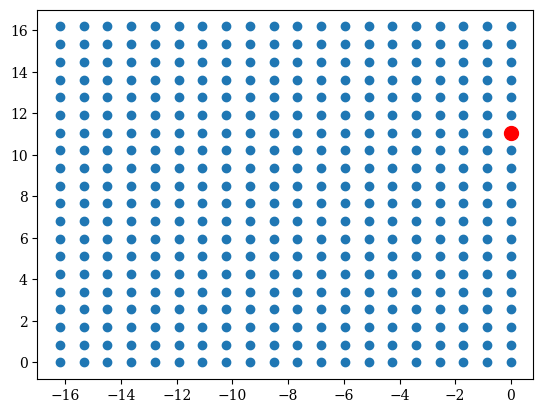

In [127]:
plt.scatter(positions_rot[:, 0] * rad_to_arcsec, positions_rot[:, 1] * rad_to_arcsec)
plt.scatter(positions_rot[13, 0]*rad_to_arcsec, positions_rot[13, 1]*rad_to_arcsec, c='red', s=100, label='Closest Approach')

In [161]:
phi_0/np.pi#+2*np.pi

-0.6616347913316158

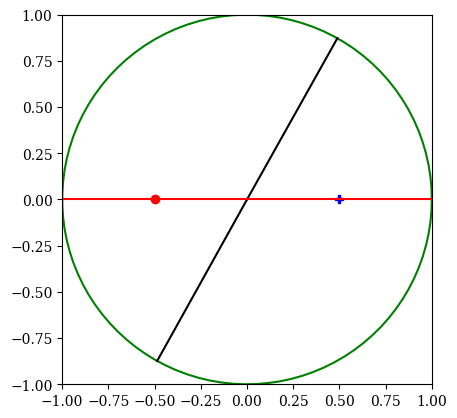

In [174]:

r = 1
def deg2rad(deg):
    return deg * pi / 180
angles = np.linspace(0 * np.pi, 2 * np.pi, 100) 
xs = np.cos(angles)
ys = np.sin(angles)
plt.plot(xs, ys, color = 'green')

plt.plot(r-0.5, 0, marker = 'P', color = 'blue')
plt.plot(-r+0.5, 0, marker = 'o', color = 'red')
plt.plot([0, r * np.cos(phi_0)], [0, r * np.sin(phi_0)], color = "black")
plt.plot([0, r * np.cos(1.06)], [0, r * np.sin(1.06)], color = "black")

plt.plot([r, -r], [0, 0], color = 'red')
plt.xlim(-r, r)
plt.ylim(-r, r)
plt.gca().set_aspect('equal')

In [171]:
np.arctan((((position_04[13,0] -4000)*theta_step* rad_to_arcsec)/((position_04[13,1] -4000)*theta_step* rad_to_arcsec)))

np.float64(1.0630056537797883)

In [ ]:
np.arctan(((position_04[13,1] -4000)*theta_step* rad_to_arcsec)/((position_04[13,0] -4000)*theta_step* rad_to_arcsec))

np.float64(0.5077906730151083)

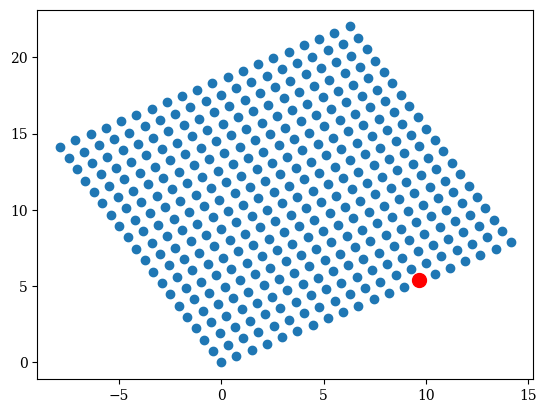

In [147]:

plt.scatter((position_04[:,0] -4000)*theta_step* rad_to_arcsec, (position_04[:,1] -4000)*theta_step* rad_to_arcsec)
plt.scatter((position_04[13,0] -4000)*theta_step* rad_to_arcsec,
             (position_04[13,1] -4000)*theta_step* rad_to_arcsec, c='red', s=100, label='Closest Approach')

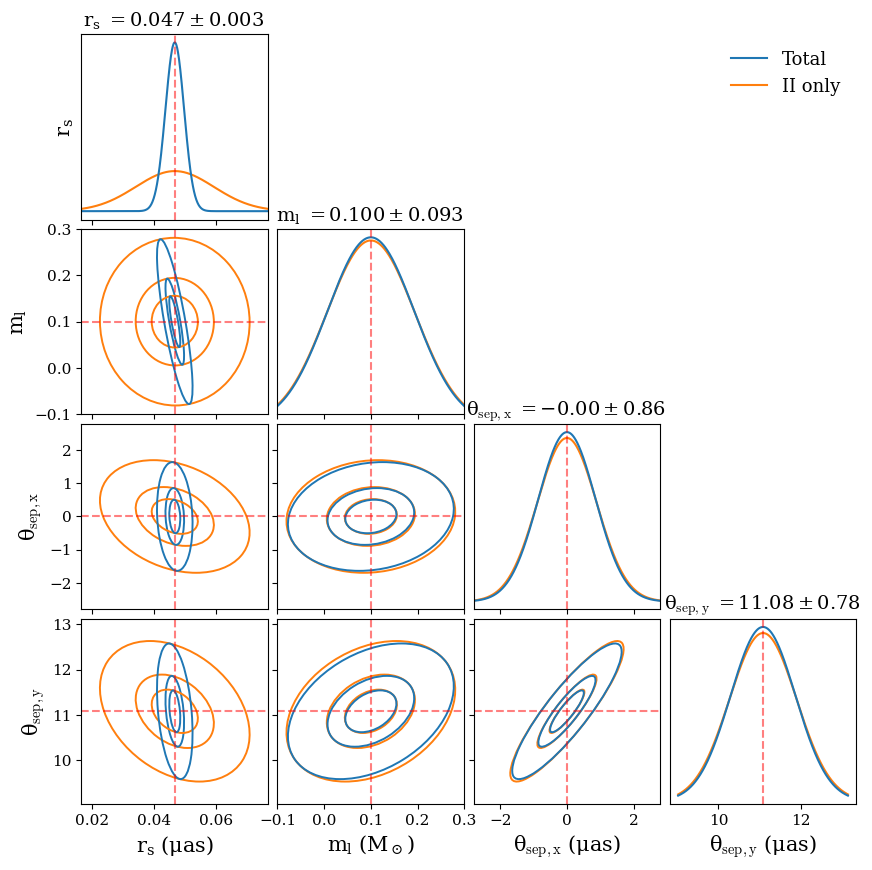

In [130]:
idx=13
pos_x_corner=(positions_rot[idx][0])
pos_y_corner=(positions_rot[idx][1])
mass_04_combo[idx]

titles = [r"$r_s\ (mas)$", r"$m_l\ (M_\odot)$",
          r"$\theta_{\rm sep,x}\ (mas)$", r"$\theta_{\rm sep,y}\ (mas)$"]

varlabels = [r"$r_s$", r"$m_l$", r"$\theta_{\rm sep,x}$", r"$\theta_{\rm sep,y}$"]
units = [r"$\mu as$", r"$M_\odot$", r"$\mu as$", r"$\mu as$"]
precision = [3, 3, 2, 2]

mean_vec = np.array([rad_mas, 0.1, pos_x_corner * rad_to_arcsec, pos_y_corner * rad_to_arcsec])
scales=[.03, .2, 2.8, 2.05] 
limits = np.array([[mean_vec[0]-scales[0], mean_vec[0]+scales[0]], [mean_vec[1]-scales[1], mean_vec[1]+scales[1]],
                   [mean_vec[2]-scales[2], mean_vec[2]+scales[2]], [mean_vec[3]-scales[3], mean_vec[3]+scales[3]]])

cov1 = cov_combo_04[idx] 
cov2 = cov_04[idx]

ndim = len(varlabels)

fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(ndim, ndim, hspace=0.05, wspace=0.05)

axes = np.empty((ndim, ndim), dtype=object)
percentiles = [0.16, 0.84]
colors = ["C0", "C0", "C0"]  # or different colors/styles
linewidths = [0.8, 0.8]

colors2 = ["C1", "C1", "C1"]

for i in range(ndim):
    for j in range(ndim):

        if i < j:
            axes[i, j] = fig.add_subplot(gs[i, j])
            axes[i, j].axis("off")
            continue

        if i == j:
            axes[i, j] = fig.add_subplot(gs[i, j])
        else:
            axes[i, j] = fig.add_subplot( gs[i, j], sharex=axes[j, j],  sharey=axes[i, i] )

for i in range(ndim):
    for j in range(ndim):
        ax = axes[i,j]
        if i < j:
            continue

        if i == j:
            # 1D marginal
            sigma1 = np.sqrt(cov1[i,i])
            sigma2 = np.sqrt(cov2[i,i])
            x = np.linspace(limits[j][0], limits[j][1], 500)#mean_vec[i]-4*sigma1, mean_vec[i]+4*sigma1, 500)
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma2), color="C1")
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma1), color="C0")
            ax.set_yticks([])
            ax.tick_params(left=False)
            nd = precision[i]
            ax.set_title(fr"{varlabels[i]} $= {mean_vec[i]:.{nd}f} \pm {sigma1:.{nd}f}$ ",
                         fontsize=14)
            ax.axvline(mean_vec[[j,i]][1], color='r', linestyle='dashed', alpha=.5)
        else:
            # 2D ellipse
            mean_ij = mean_vec[[j,i]]
            cov1_ij = cov1[np.ix_([j,i],[j,i])]
            cov2_ij = cov2[np.ix_([j,i],[j,i])]
            ax.set_xlim(limits[j][0], limits[j][1])#mean_vec[j]-4*np.sqrt(cov1[j,j]),
                       # mean_vec[j]+4*np.sqrt(cov1[j,j]))
            ax.set_ylim(limits[i][0], limits[i][1])
                        #mean_vec[i]+4*np.sqrt(cov1[i,i]))
            ax.axvline(mean_ij[0], color='r', linestyle='dashed', alpha=.5)
            ax.axhline(mean_ij[1], color='r', linestyle='dashed', alpha=.5)
            plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=1, edgecolor="C1", linewidth=1.4)
            plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=1, edgecolor="C0", linewidth=1.4)

            for p, c, lw in zip(percentiles, colors2, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)
            for p, c, lw in zip(percentiles, colors, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)

        ax.tick_params(labelsize=11)
            
for i in range(ndim):
    for j in range(ndim):
        ax = axes[i, j]
        if i != ndim - 1:
            ax.tick_params(labelbottom=False)
        if j != 0:
            ax.tick_params(labelleft=False)
        #if i!=j+1:
        ax.set_xlabel(f"{varlabels[j]} ({units[j]})", fontsize=15)
        if i>-1 and j==0:
            ax.set_ylabel(f"{varlabels[i]}", fontsize=15)
        
axes[0, -1].plot([], [], color="C0", label="Total")
axes[0, -1].plot([], [], color="C1", label="II only")
axes[0, -1].legend(frameon=False, fontsize=13)

title=r'$\theta_{{sep}} = [$' + str(format(pos_x_corner*rad_to_arcsec, '.2f')) + ', ' + str(format(pos_y_corner*rad_to_arcsec, '.2f')) + r'$]\ \mu$as'
#plt.text(-5.5, 2.35, title, fontsize=18);
#plt.text(-25, 1.45, r'$\theta_{{sep}} = [-0.31,  0.57]\ \mu$as', fontsize=18);
#plt.show()

plt.savefig('Figures/corner04_ell.pdf', bbox_inches='tight')
#FileLink('../Figures/corner01_res.pdf')

### Interpolate errors

In [11]:
n = int(np.sqrt(len(x_rot)))

x_grid = np.unique(positions_rot[:, 0].round(decimals=15))#*theta_step * image_size
x_grid = np.concat((x_grid, (-x_grid[len(x_grid)-2::-1])))
y_grid = np.unique(positions_rot[:, 1].round(decimals=15))#*theta_step * image_size
y_grid = np.concat((-y_grid[::-1], (y_grid[1:])))

rad_grid  = rad_04_combo.reshape(n, n)
mass_grid = mass_04_combo.reshape(n, n)
xpos_grid = posx_04_combo.reshape(n, n)
ypos_grid = posy_04_combo.reshape(n, n)


In [12]:
rad_grid  = one_quad_to_full(rad_04_combo, n)
mass_grid = one_quad_to_full(mass_04_combo, n)
xpos_grid = one_quad_to_full(posx_04_combo, n)
ypos_grid = one_quad_to_full(posy_04_combo, n)


In [13]:
# Build interpolators
rad_spline  = RegularGridInterpolator([x_grid, y_grid], rad_grid, method='linear')
mass_spline = RegularGridInterpolator([x_grid, y_grid], mass_grid, method='linear')
xpos_spline = RegularGridInterpolator([x_grid, y_grid], xpos_grid, method='linear') #takes position in radians, returns in mas
ypos_spline = RegularGridInterpolator([x_grid, y_grid], ypos_grid, method='linear')

In [14]:
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
#mass_interp = mass_spline.ev(X_fine.ravel(), Y_fine.ravel()).reshape(Y_fine.shape)

In [15]:
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)
rad_interp = rad_spline(points).reshape(X_fine.shape)
mass_interp = mass_spline(points).reshape(X_fine.shape)
xpos_interp = xpos_spline(points).reshape(X_fine.shape)
ypos_interp = ypos_spline(points).reshape(X_fine.shape)

### Interpolate fisher matricies for m=0.8

In [16]:
f_combo_04=[]
for i in range(len(cov_combo_04)):
    f_combo_04.append(np.linalg.inv(cov_combo_04[i]))
f_combo_04=np.array(f_combo_04)
f_combo_04 = f_combo_04.reshape(n, n, 4, 4)
f_combo_04  = matrix_to_full(f_combo_04, n)

In [17]:
splines_f04 = [[RectBivariateSpline(x_grid, y_grid, f_combo_04[:, :, i, j])#, s=1e-24)
            for j in range(4)] for i in range(4)]
def fisher_spline(pos_arr):
    x=pos_arr[0]
    y=pos_arr[1]
    return np.array([[splines_f04[i][j](x, y)[0,0] for j in range(4)] for i in range(4)])

In [18]:
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 400)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 400)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')


In [19]:
Z_det=np.empty((len(fine_grid_x), len(fine_grid_y)))
for i, x in enumerate(fine_grid_x):
    for j, y in enumerate(fine_grid_y):
       
        f_original = fisher_spline([x, y])      
        Z_det[i, j] = np.linalg.det(f_original) 

In [20]:
interpolators = [[None for j in range(4)] for i in range(4)]

for i in range(4):
    for j in range(4):
        # Linear interpolation; 'bounds_error=False' allows extrapolation if needed
        interpolators[i][j] = RegularGridInterpolator(
            (x_grid, y_grid),
            f_combo_04[:, :, i, j], bounds_error=False, method='linear', fill_value=np.nan)
def fisher_interp_linear(pos):
    x, y = pos
    M = np.zeros((4, 4))
    for i in range(4):
        for j in range(4):
            M[i, j] = interpolators[i][j]([x, y])
    # enforce symmetry
    M = 0.5 * (M + M.T)
    return M
def fisher_interp_grid(pos):
    x, y = pos[:, 0], pos[:, 1]
    N = len(x)

    M = np.zeros((N, 4, 4))
    for i in range(4):
        for j in range(4):
            M[:, i, j] = interpolators[i][j](np.column_stack((x, y)))

    # enforce symmetry on the last two axes only
    M = 0.5 * (M + np.swapaxes(M, -1, -2))
    return M

In [21]:
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)
Fvals_interp = fisher_interp_grid(points).reshape((200,200,4,4))


### Interpolate chi^2, centroids

In [22]:
chi_grid  = one_quad_to_full(chi_combo_04, n)

fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)

chi_spline  = RegularGridInterpolator([x_grid, y_grid], chi_grid, bounds_error=False, method='linear', fill_value=np.nan)
chi_interp  = chi_spline(points).reshape(X_fine.shape)

In [23]:

centroids=centroids.reshape(n,n,2,4)
Jcent_grid  = Jac_to_full(centroids, n)

interpolators_cent=[[None for i in range(4)] for a in range(2)]

for a in range(2):        # centroid x/y
    for i in range(4):    # parameters
        interpolators_cent[a][i] = RegularGridInterpolator(
        (x_grid, y_grid),
        Jcent_grid[:, :, a, i], bounds_error=False, method='linear', fill_value=np.nan)

def Jcent_interp(pos):
    x, y = pos
    J = np.zeros((2, 4))
    for a in range(2):
        for i in range(4):
            J[a, i] = interpolators_cent[a][i]([x, y])
    return J

cent_pres  = one_quad_to_full(cent_pres, n)
cent_spline = RegularGridInterpolator([x_grid, y_grid], cent_pres, method='linear', fill_value=np.nan)
cent_interp = cent_spline(points).reshape(X_fine.shape)

sigma_c1  = one_quad_to_full(sigma_c1, n)
sigma_c1_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c1, method='linear', fill_value=np.nan)
sigma_c1_interp = sigma_c1_spline(points).reshape(X_fine.shape)

sigma_c2  = one_quad_to_full(sigma_c2, n)
sigma_c2_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c2, method='linear', fill_value=np.nan)
sigma_c2_interp = sigma_c2_spline(points).reshape(X_fine.shape)

In [24]:
chi_grid_II  = one_quad_to_full(chis_04_II, n)
chi_spline_II  = RegularGridInterpolator([x_grid, y_grid], chi_grid_II, bounds_error=False, method='linear', fill_value=np.nan)

chi_grid_mag  = one_quad_to_full(chis_04_mag, n)
chi_spline_mag  = RegularGridInterpolator([x_grid, y_grid], chi_grid_mag, bounds_error=False, method='linear', fill_value=np.nan)

/mnt/home/amoran/lensing/M01/M04/Figures/chi04.pdf

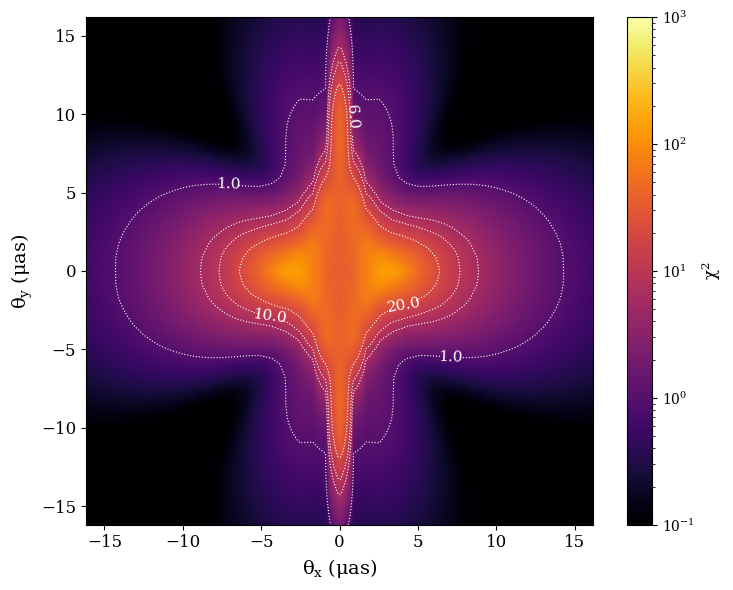

In [25]:
Z = np.flipud(chi_interp).T
X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
#extent = [np.min(fine_grid_x), np.max(fine_grid_x), np.min(fine_grid_y), np.max(fine_grid_y)]
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

levels=[1, 6, 10, 20]
# Mask values > 6
#masked_Z = np.ma.masked_where(Z > 6, Z)

fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(Z, origin='lower', extent=extent, cmap='inferno', norm=matplotlib.colors.LogNorm(vmin=.1,vmax=1000),)
contours = ax.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax.clabel(contours, inline=True, fontsize=11, fmt="%.1f")

# Grey overlay for chi > 6 (where macrolensing wins)
#grey_mask = np.ma.masked_where(Z > 6, Z)
#ax.imshow(grey_mask, origin='lower', extent=extent, cmap='Greys', alpha=0.5, vmin=0, vmax=0)  # semi-transparent
cbar = plt.colorbar(im, ax=ax, fraction=0.045, pad=.03)
cbar.set_label(r'$\chi^2$', fontsize=12)

ax.tick_params(axis='both', which='major', labelsize=12)
ax.tick_params(axis='both', which='minor', labelsize=10)

ax.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()


plt.savefig('Figures/chi04.pdf', bbox_inches='tight')
FileLink('Figures/chi04.pdf')

### Error Plots

In [26]:
orig_map=plt.cm.get_cmap('cividis')

# reversing the original colormap using reversed() function
reversed_map = orig_map.reversed()

bulk_vel=400
bulk_vel_err=100
vel_disp=178
vel_disp_err=35

dist_x = get_velocities(np.array([0, np.sqrt(bulk_vel**2+vel_disp**2)*1e5]), B_matrix, z_l, D_l)
mu_x=np.sqrt(dist_x[0]**2+dist_x[1]**2)*356*24*3600*rad_to_arcsec

/tmp/ipykernel_3940361/4128783968.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  orig_map=plt.cm.get_cmap('cividis')


In [158]:
np.min(Z)

np.float64(0.3575821351877235)

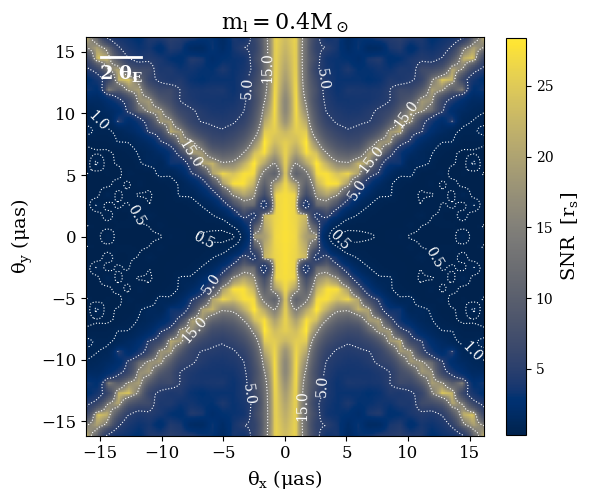

In [157]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    
extent2 = [-theta_max, theta_max, -theta_max, theta_max]    #left right bottom top 

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = rad_mas/np.flipud(rad_interp).T

levels=[0.5, 1, 5, 15]
im=ax1.imshow(Z, origin='lower',  cmap=orig_map, extent=extent, )
              # norm=matplotlib.colors.LogNorm(vmin=.05, vmax=1),)#, vmax=1.3, vmin=.1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
cbar.set_label(r'SNR $\ [r_s]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

#scale thing
scale_length = 2*theta_E_4*rad_to_arcsec    

# pick a position for the bar 
x_start = np.min(fine_grid_x) - 4.6 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text((x_start + x_end) / 2, y_pos * .85, r"$ 2 \ \theta_{E}$", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')#, backgroundcolor='white')


ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
plt.title(r'$m_l=0.4M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)


ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()

plt.savefig('Figures/rad_04.pdf', bbox_inches='tight')
#FileLink('Figures/rad_04.pdf')

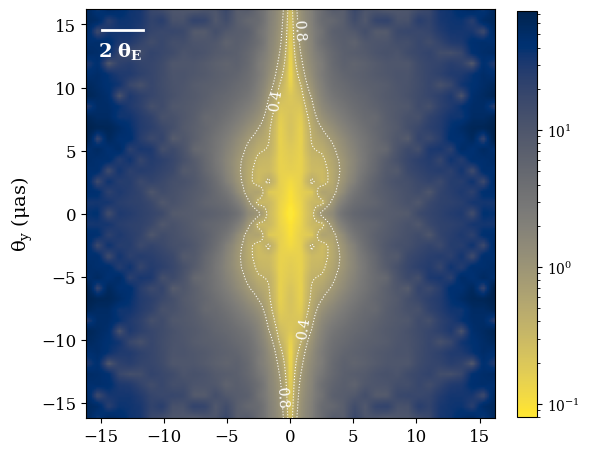

In [37]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    
extent2 = [-theta_max, theta_max, -theta_max, theta_max]    #left right bottom top 

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(mass_interp).T

levels=[ .4, .8]
im=ax1.imshow(np.flipud(mass_interp).T, origin='lower', cmap=reversed_map, 
              norm=matplotlib.colors.LogNorm(vmin=8e-2), extent=extent)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
#cbar.set_label(r'$ \sigma \ [m_l]\  (M_\odot)$', fontsize=14)

#contours
scale_length = 2*theta_E_4*rad_to_arcsec    

contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")
x_start = np.min(fine_grid_x) - 4.6 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text((x_start-.3 + x_end) / 2, y_pos * .83, r"$ 2 \ \theta_{E}$", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')#, backgroundcolor='white')


ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
#plt.title(r'$m_l=0.8M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)


#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()


plt.savefig('Figures/mass_04.pdf', bbox_inches='tight')
#FileLink('Figures/mass_04.pdf')

In [36]:
pos_mag

array([[22.89577805, 22.78101443, 22.66683776, ..., 22.66683776,
        22.78101443, 22.89577805],
       [22.78101443, 22.66566973, 22.55090907, ..., 22.55090907,
        22.66566973, 22.78101443],
       [22.66683776, 22.55090907, 22.43556141, ..., 22.43556141,
        22.55090907, 22.66683776],
       ...,
       [22.66683776, 22.55090907, 22.43556141, ..., 22.43556141,
        22.55090907, 22.66683776],
       [22.78101443, 22.66566973, 22.55090907, ..., 22.55090907,
        22.66566973, 22.78101443],
       [22.89577805, 22.78101443, 22.66683776, ..., 22.66683776,
        22.78101443, 22.89577805]], shape=(200, 200))

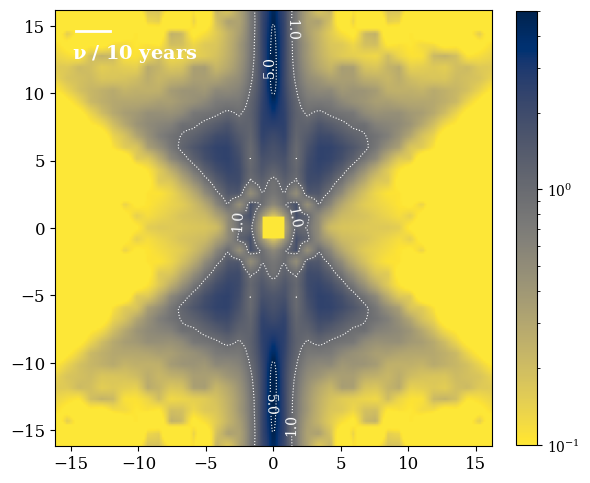

In [37]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
pos_mag=np.sqrt(X**2+Y**2)
Z = np.sqrt(np.flipud(xpos_interp).T**2+np.flipud(xpos_interp).T**2)
levels=[1, 5]
im=ax1.imshow(pos_mag/Z, origin='lower',cmap=reversed_map,norm=matplotlib.colors.LogNorm(vmin=.1, vmax=5), extent=extent)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
#cbar.set_label(r'$ \sigma \ [\theta_{\text{sep}}] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, pos_mag/Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

scale_length=mu_x*10
x_start = np.min(fine_grid_x) - 5.8* scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text(x_start+4.35, y_pos * .83, r"$\nu \ / $ 10 years", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')#, backgroundcolor='white') # this is lensed along the x axis!!

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
plt.tight_layout()


#plt.savefig('Figures/pos_04.pdf', bbox_inches='tight')
#FileLink('../Figures/pos_04.pdf')

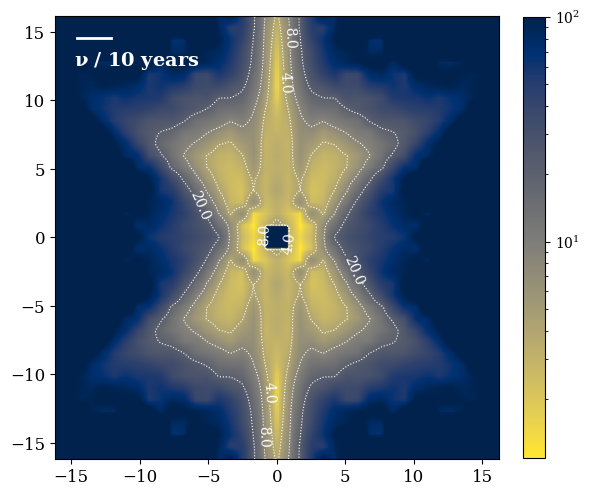

In [179]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.sqrt(np.flipud(xpos_interp).T**2+np.flipud(xpos_interp).T**2)
levels=[4, 8, 20]
im=ax1.imshow(Z, origin='lower',cmap=reversed_map,norm=matplotlib.colors.LogNorm(vmax=100), extent=extent)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
#cbar.set_label(r'$ \sigma \ [\theta_{\text{sep}}] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

scale_length=mu_x*10
x_start = np.min(fine_grid_x) - 5.8* scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text(x_start+4.35, y_pos * .83, r"$\nu \ / $ 10 years", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')#, backgroundcolor='white') # this is lensed along the x axis!!

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
plt.tight_layout()


plt.savefig('Figures/pos_04.pdf', bbox_inches='tight')
#FileLink('../Figures/pos_04.pdf')

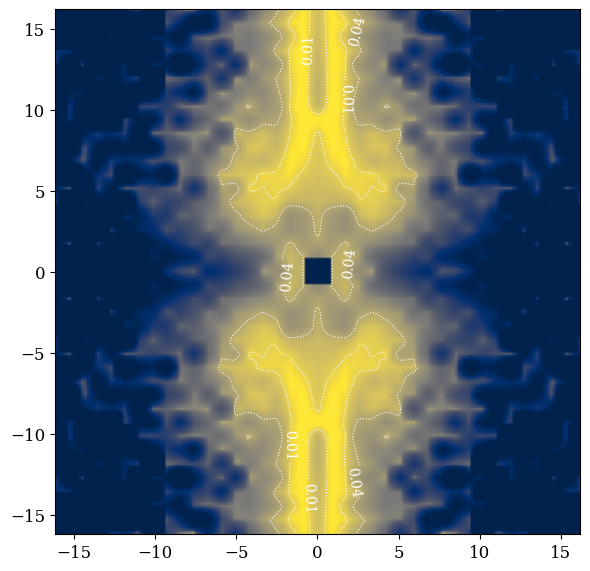

In [30]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c2_interp).T
levels=[.01, .04]

im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=5e-3, vmax=1e1))#,  vmax=68, vmin=1)
#cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03)
#cbar.set_label(r'$ \sigma \ [|\theta_{\text{c}}|] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.2f")

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
#plt.title(r'$m_l=0.8M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)

#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
#ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()


plt.savefig('Figures/thetac2_04.pdf', bbox_inches='tight')


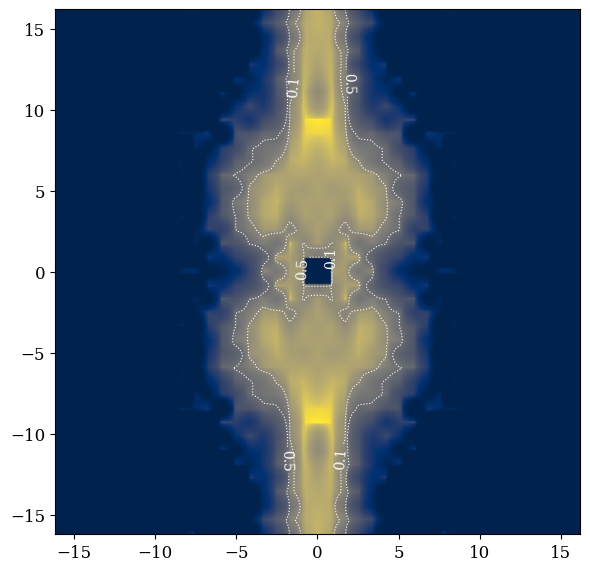

In [32]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c1_interp).T
levels=[.1, .5]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=1e-3, vmax=5e1))#,  vmax=68, vmin=1)
#cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03)
#cbar.set_label(r'$ \sigma \ [|\theta_{\text{c}}|] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
#plt.title(r'$m_l=0.8M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)

#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
#ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()


plt.savefig('Figures/thetac1_04.pdf', bbox_inches='tight')


### Uncertainties as a function of min impact parameter

In [27]:
def average_errors_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift, lens_dist, B_matrix, dist, chi_spline,
                  dt_days=182.0, max_time_days= 5 * 365.0, n_its=100, fisher_spline=fisher_interp_linear):
    """
    Simulate random trajectories of a lensing system and compute average uncertainties and covariances for 
    trajectory parameters and centroid positions.

    Inputs:
    bulk_vel: float, lensing galaxy bulk vel in km/s
    bulk_vel_err: float, km/s
    vel_disp: float, vel dist of the stars in the lensing galaxy, km/s
    vel_disp_err: float, km/s
    theta_max: radians
    N: int, # of steps in each simulated trajectory
    redshift: float, source z
    lens_dist: float, lens distance (in same units as used in simulations)
    B_matrix: inv_jacobian of the macrolensing stuff
    dist: lens distance in cm 
    chi_spline , fisher_spline: callable default `fisher_interp_linear` for fisher_spline
    dt_days: float, optional. time step in days for trajectory simulation (default 182.0)
    max_time_days: float, optional, max total simulation time in days (default 5 years)
    n_its: int, optional, how many lenses to simulate motion for averaving    
    
    Outputs:
    cov_thetas: array: 6x6 cov matrixies for each lens trajectory
    cov_avg: average across trajectories
    uncert_thetas: array, len 6, uncertaintiy in theta space for each traj
    uncert_avg: average of that
    vels: the velocity we drew in each trajectory realization
    chi_all: array: total chi^2 values summed over each trajecotry
    retries: list of int, Number of retries needed for each trajectory to avoid NaNs in uncertainties.
    Jcents: array of 2x2 centroid covariance matricies combiend over each traj.
    """
    
    fisher_thetas=[]
    cov_thetas=[]
    uncert_thetas=[]
    vels=[]
    chi_all=[]
    retries=[]
    Jcents=[]
    acc_covs=[]
    acc_sigmas=[]
    for it in range(n_its):
        test_traj= sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift,
                                         lens_dist, B_matrix, dist,  dt_days=182.0, max_time_days= max_time_days)    
        positions_traj=test_traj['positions_rad']
        fisher_alpha=[]
        uncert_alphas=[]
        chi_traj=[]
        centJ_traj=[]
        vels.append(test_traj['velocity_kms'])
        for position_i in positions_traj:
            fisher_alpha.append(fisher_spline(position_i))
            uncert_alphas.append(parameter_uncertainties(fisher_alpha[-1], theta_step, printout=False)[1])
            chi_traj.append(chi_spline(position_i))
            centJ_traj.append(Jcent_interp(position_i))

            
        retry=0
        fisher_theta_traj=(f_alpha_to_f_Theta(fisher_alpha, test_traj['times_days']*(3600*24)))
        cov_Theta, uncert_Theta = parameter_uncertainties(fisher_theta_traj, theta_step, printout=False, numstars=1)
        while np.any(np.isnan(uncert_Theta)):
            retry += 1
            test_traj= sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift,
                                         lens_dist, B_matrix, dist,  dt_days=182.0, max_time_days= max_time_days)
            positions_traj=test_traj['positions_rad']
            fisher_alpha=[]
            uncert_alphas=[]
            chi_traj=[]
            Jcent_traj=[]
            vels.append(test_traj['velocity_kms'])
            for position_i in positions_traj:
                fisher_alpha.append(fisher_spline(position_i))
                uncert_alphas.append(parameter_uncertainties(fisher_alpha[-1], theta_step, printout=False)[1])
                chi_traj.append(chi_spline(position_i))
                Jcent_traj.append(Jcent_interp(position_i))
            fisher_theta_traj=(f_alpha_to_f_Theta(fisher_alpha, test_traj['times_days']*(3600*24)))
            cov_Theta, uncert_Theta = parameter_uncertainties(fisher_theta_traj, theta_step, printout=False, numstars=1)
        
        retries.append(retry)  
        centJ_traj=np.array(centJ_traj)
        centJ_traj = np.array([j.reshape(2,4) for j in centJ_traj])
        uncert_alphas=np.array(uncert_alphas)
        chi_all.append(np.sum(chi_traj))
        centroid_cov_traj = []

        for t in range(len(positions_traj)):
            J = centJ_traj[t]          # shape (2,4)
            C_alpha = np.linalg.inv(fisher_alpha[t])  # shape (4,4)
            C_cent = J @ C_alpha @ J.T    # shape (2,2)
            centroid_cov_traj.append(C_cent)
        

        centroid_cov_traj = np.array(centroid_cov_traj)
        cov_acc, sigma_acc = centroid_acceleration_uncertainty(centroid_cov_traj, test_traj['times_days'])
        acc_covs.append(cov_acc)
        acc_sigmas.append(sigma_acc)
        Cinv_tot = np.zeros((2, 2))
        
        for C in centroid_cov_traj: #combine timesteps into one, so invert, combine
            Cinv_tot += np.linalg.inv(C)
        
        C_cent_tot = np.linalg.inv(Cinv_tot) #invert back
        Jcents.append(C_cent_tot)
        fisher_thetas.append(f_alpha_to_f_Theta(fisher_alpha, test_traj['times_days']*(3600*24)))
        cov_v_cm, cov_v_kms, sigma_v_kms = unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist)
        cov_Theta, uncert_Theta = parameter_uncertainties(fisher_thetas[-1], theta_step, printout=False, numstars=1)
        cov_thetas.append(cov_Theta)
        uncert_unlensed = np.array(uncert_Theta.copy())
        
        # replace last two entries 
        _,_, sigma_v_kms = unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist)
        uncert_unlensed[4] = sigma_v_kms[0]*4.848136811e-12 # correct for mas to radians
        uncert_unlensed[5] = sigma_v_kms[1]*4.848136811e-12
        
        # store full 6-element uncertainty vector
        uncert_thetas.append(uncert_unlensed)
    cov_thetas=np.array(cov_thetas)
    Jcents=np.array(Jcents)
    chi_all=np.array(chi_all)#.reshape(len(chi_all))    
    cov_avg=np.mean(cov_thetas, axis=0)
    uncert_thetas=np.array(uncert_thetas)
    uncert_avg=np.sum(uncert_thetas, axis=0)/n_its
    vels=np.array(vels)
    return cov_thetas, cov_avg, uncert_thetas, uncert_avg, vels, chi_all, retries,  Jcents, acc_sigmas

In [28]:
from II_funcs import *

In [51]:
theta_E_8 = np.sqrt(4 * G * 0.8 * 2e33 / c**2 * D_ls / (D_s * D_l))
impact_params = np.linspace(0.3 * theta_E_8, 5.9 * theta_E_8, 40)[:30]
impact_params_fine=np.linspace(0.2*theta_E_8, impact_params[-6], 60)
chi_tots, uncert_avgs, n_retries = [], [], []
chi_dists, uncert_dists = [], []
cent_all, acc_sigmas = [], []

for impact_param in impact_params_fine:
    (cov_theta_all, cov_avg, uncert_theta_all, uncert_avg,
        vels, chi_traj_avg, n_r, cent_tot, acc_sigma) = average_errors_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err,
                                                    np.max(x_grid), 8000, z_l, D_l, B_matrix, impact_param, chi_spline,
                                                    fisher_spline=fisher_interp_linear, n_its=6000, max_time_days=2.5 * 365.0)

    chi_tots.append(chi_traj_avg.mean())
    uncert_avgs.append(uncert_avg)
    n_retries.append(n_r)
    chi_dists.append(chi_traj_avg)
    uncert_dists.append(uncert_theta_all)
    cent_all.append(cent_tot)
    acc_sigmas.append(acc_sigma)

results = {
    "impact_params": impact_params_fine,
    "chi_tots": np.array(chi_tots),
    "cent_all": np.array(cent_all),
    "uncert_avgs": np.array(uncert_avgs),
    "n_retried": np.array(n_retries),
    "chi_dists": np.array(chi_dists, dtype=object),
    "uncert_dists": np.array(uncert_dists, dtype=object),
    "acc_sigmas": np.array(acc_sigmas, dtype=object),}

filename = "avgs_04_0504_fine.npz"

try:
    existing = np.load(filename, allow_pickle=True)

    combined = {}
    for key, new_vals in results.items():
        old_vals = existing[key]

        if new_vals.ndim > 1 and key == "uncert_avgs":
            combined[key] = np.vstack([old_vals, new_vals])
        else:
            combined[key] = np.hstack([old_vals, new_vals])

except FileNotFoundError:
    combined = results

np.savez(filename, **combined)

/tmp/ipykernel_2579656/3038925516.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  M[i, j] = interpolators[i][j]([x, y])
/tmp/ipykernel_2579656/3547704378.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  J[a, i] = interpolators_cent[a][i]([x, y])


In [33]:
uniq.shape

(30,)

In [6]:
data = np.load("avgs_04_0504_fine.npz", allow_pickle=True)

impact_params_all = data["impact_params"]
chi_all= data["chi_tots"]
uncert_all = data["uncert_avgs"]
chi_dists_all = data["chi_dists"]
uncert_dists_all = data["uncert_dists"] 

uniq = np.unique(impact_params_all)
chi_mean   = np.zeros(len(uniq))
uncert_mean = np.zeros((len(uniq), uncert_all.shape[1]))

for i, u in enumerate(uniq):
    mask = impact_params_all == u
    chi_mean[i]   = chi_all[mask].mean()
    uncert_mean[i] = uncert_all[mask].mean(axis=0)

impact_params = uniq
chi_full=np.array(chi_dists_all)
uncert_full=np.array(uncert_dists_all)

In [7]:
chi_dists_all.shape

(60, 16000)

In [8]:
# calcualte the percentiles for all this for plotting purposes
cent_all=data["cent_all"]
cent_precision1=np.linalg.det(cent_all)
cent_nans=np.copy(cent_all)
cent_nans[np.isnan(cent_all)]=0

cent_precision2=np.min(np.linalg.eigvals(cent_nans), axis=2)

sigma_cent1_mean = np.mean(cent_precision1, axis=-1)
sigma_cent2_mean = np.mean(cent_precision2, axis=-1)

sigma_cent1_84 = np.nanpercentile(cent_precision1, 84, axis=-1)
sigma_cent2_84 = np.nanpercentile(cent_precision2, 84, axis=-1)

sigma_cent1_16 = np.nanpercentile(cent_precision1, 16, axis=-1)
sigma_cent2_16 = np.nanpercentile(cent_precision2, 16, axis=-1)

sigma_cent1_50 = np.nanpercentile(cent_precision1, 50, axis=-1)
sigma_cent2_50 = np.nanpercentile(cent_precision2, 50, axis=-1)

In [9]:
acc_sigmas=data["acc_sigmas"]
acc_sigma_mean=np.mean(acc_sigmas, axis=-1)
acc_sigma_84 = np.nanpercentile(acc_sigma_mean, 84, axis=-1)
acc_sigma_16 = np.nanpercentile(acc_sigma_mean, 16, axis=-1)
acc_sigma_50 = np.nanpercentile(acc_sigma_mean, 50, axis=-1)


In [10]:
#check that all of these are in the area under chi^2=10, and they are!
n_retrys=data['n_retried']
cut=0
for i in range(len(n_retrys)):
    tries=np.sum(n_retrys[i])
    if tries>0:
        print("pos", np.array(impact_params/theta_E_8)[i], ':', tries)
    if np.percentile(chi_full, 50, axis=1)[i]<10 and cut==0:
        print('cutoff is ', np.array(impact_params/theta_E_8)[i])
        print('limit x axis to ', np.array(impact_params/theta_E_8)[i-1])
        xlim=np.array(impact_params/theta_E_8)[i-1]
        cut=10
        

cutoff is  3.7461538461538466
limit x axis to  3.686049543676663


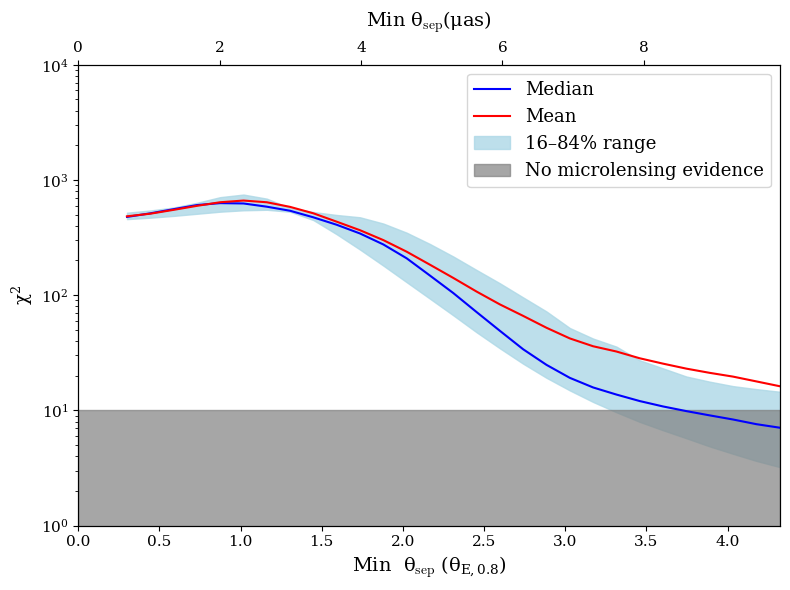

In [64]:
p16= np.array(np.percentile(chi_full, 16, axis=1), dtype=float)
p84 = np.array(np.percentile(chi_full, 84, axis=1), dtype=float)
xlim_real=xlim*1.2
fig,ax = plt.subplots(figsize=(8,6))

ax.plot(impact_params / theta_E_8, np.percentile(chi_full, 50, axis=1), color='blue', label='Median')
ax.plot(impact_params / theta_E_8, chi_mean, label='Mean', color='red')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim_real*theta_E_8*rad_to_arcsec)


ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.axhspan(0,10, label='No microlensing evidence', alpha=.7, color='gray')
ax.set_ylabel(r'$\chi^2$', fontsize=13)
ax.set_xlabel(r'Min  $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_yscale('log')
ax.set_xlim(0, xlim_real)
ax.set_ylim(1, 1e4)
ax.legend(fontsize=13)
fig.tight_layout() # 5 years
plt.savefig('Figures/chi_traj_04.pdf')

#### Uncertainties 

In [41]:
# load in the averages
uncert_rads_avg =np.array(np.percentile(uncert_full[:,:,0], 50, axis=1))
uncert_mass_avg =np.array(np.percentile(uncert_full[:,:,1], 50, axis=1))
uncert_xpos_avg =np.array(np.percentile(uncert_full[:,:,2], 50, axis=1))
uncert_ypos_avg =np.array(np.percentile(uncert_full[:,:,3], 50, axis=1))
uncert_xvel_avg =np.array(np.percentile(uncert_full[:,:,4], 50, axis=1))
uncert_yvel_avg =np.array(np.percentile(uncert_full[:,:,5], 50, axis=1))
s_to_yr = 1 / (365.25 * 86400)  


In [63]:
import pandas as pd

In [111]:
df=pd.DataFrame((np.array((impact_params/theta_E_8, uncert_rads_avg, uncert_mass_avg, 
                        uncert_xpos_avg, uncert_ypos_avg, uncert_xvel_avg, uncert_yvel_avg, acc_sigma_50* rad_to_arcsec / s_to_yr**2)).T),
                        columns=['impact_param', 'uncert_rad', 'uncert_mass', 'uncert_xpos', 'uncert_ypos', 'uncert_xvel', 'uncert_yvel', 
                                 'acc_sigma [mas/yr^2]'])

df

,impact_param,uncert_rad,uncert_mass,uncert_xpos,uncert_ypos,uncert_xvel,uncert_yvel,acc_sigma [mas/yr^2]
0,0.3,0.000494,0.023186,0.533687,0.590147,417.971802,1148.045855,0.142907
1,0.44359,0.000498,0.024081,0.461607,0.514967,429.926008,1109.72335,0.138641
2,0.587179,0.000501,0.02515,0.389544,0.45857,433.530675,1082.029136,0.125687
3,0.730769,0.000504,0.026679,0.360874,0.431374,437.310181,1054.292621,0.114331
4,0.874359,0.000506,0.027753,0.354055,0.41335,432.354561,1040.224666,0.09239
5,1.017949,0.000515,0.027746,0.354604,0.351679,387.572623,922.395452,0.065813
6,1.161538,0.000542,0.026915,0.360476,0.265951,337.674996,738.033289,0.077112
7,1.305128,0.000586,0.028696,0.388613,0.221598,328.113286,665.343475,0.09599
8,1.448718,0.000616,0.031948,0.408485,0.212956,338.84332,661.343367,0.093879
9,1.592308,0.000638,0.035204,0.407149,0.223552,362.817442,682.872555,0.082959


In [26]:
xlim

np.float64(3.6025641025641026)

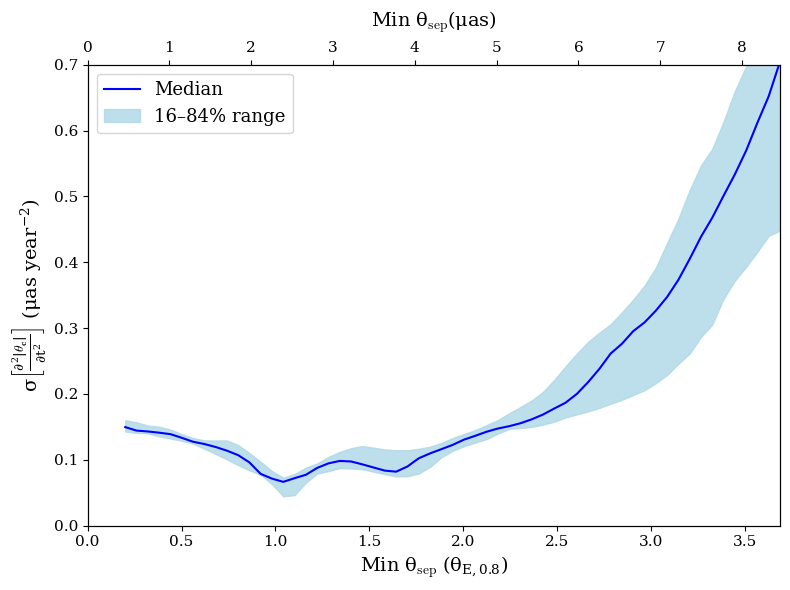

In [46]:

s_to_yr = 1 / (365.25 * 86400)  
p16 = acc_sigma_16* rad_to_arcsec / s_to_yr**2
p84= acc_sigma_84* rad_to_arcsec / s_to_yr**2

fig,ax = plt.subplots(figsize=(8,6))
ylim=.7
ax.plot(impact_params / theta_E_8, acc_sigma_50*rad_to_arcsec/s_to_yr**2, color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

#ticks_top=np.linspace(theta_E_8[0]*rad_to_arcsec, np.round(xlim)*theta_E_8[0]*rad_to_arcsec, 6) 

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0, xlim*theta_E_8*rad_to_arcsec)

#ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14);
ax.set_ylabel(r"$\sigma \left[ \frac{\partial^2 |\mathbf{\theta_{c}}|}{\partial t^2} \right]$ ($\mu$as year$^{-2}$)",  fontsize=14)
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)

ax.legend(fontsize=13)
fig.tight_layout()

plt.savefig('Figures/thetac_acc_04.pdf')

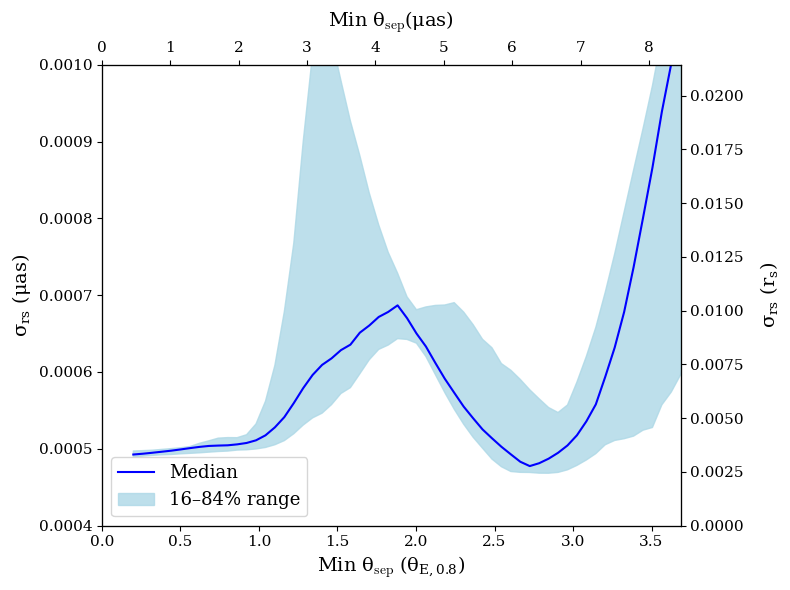

In [76]:
p16 = np.array(np.percentile(uncert_full[:,:,0], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,0], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6))
ylim=.001
ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,0], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ticks_top=np.linspace(theta_E_8*rad_to_arcsec, 8*theta_E_8*rad_to_arcsec, 6) 

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
ax_right.set_ylabel(r'$\sigma_{rs}$ ($r_s$)',  fontsize=14, labelpad=10)
ax_right.set_ylim(0,ylim/rad_mas)

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14);
ax.set_ylabel(r"$\sigma_{rs}$ ($\mu$as)",  fontsize=14)
ax.set_xlim(0, xlim)
ax.set_ylim(.0004, ylim)

ax.legend(fontsize=13)
fig.tight_layout()
plt.savefig('Figures/rad_traj_04.pdf')

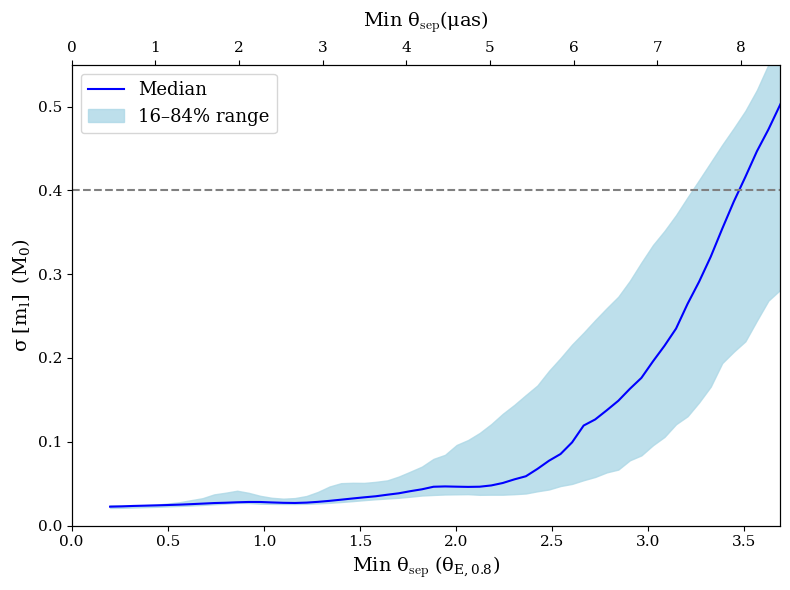

In [75]:
p16 = np.array(np.percentile(uncert_full[:,:,1], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,1], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6))
ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,1], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8*rad_to_arcsec)
ax.axhline(0.4, linestyle='dashed', color='gray')


ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [m_l]\ \ (M_0)$", fontsize=14)
ax.set_xlim(0, xlim)
ax.set_ylim(0, .55)
ax.legend(fontsize=13)
fig.tight_layout()
plt.savefig('Figures/mass_traj_04.pdf')

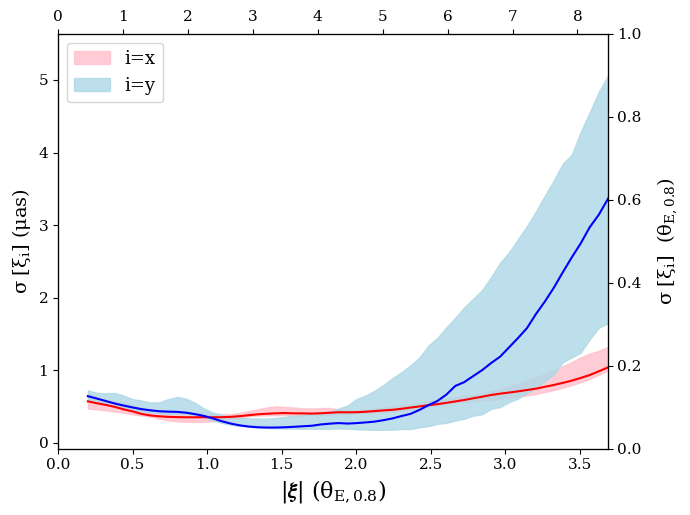

In [77]:
p16 = np.array(np.percentile(uncert_full[:,:,2], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,2], 84, axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(7,5.25))

p16_y = np.array(np.percentile(uncert_full[:,:,3], 16, axis=1), dtype=float)
p84_y = np.array(np.percentile(uncert_full[:,:,3], 84, axis=1), dtype=float)

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,2], 50, axis=1), color='red')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='i=x', color='pink')

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,3], 50, axis=1), color='blue')
ax.fill_between(impact_params / theta_E_8, p16_y, p84_y,  alpha=0.8, label='i=y', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
#ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8*rad_to_arcsec)


ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_right.set_ylabel(r'$\sigma \ [\xi_i]$  ($\theta_{E, 0.8}$)',  fontsize=14, labelpad=10)
#ax_right.set_ylim(0,ylim/(rad_to_arcsec*theta_E_8[0]))

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\theta_{E, 0.8}$)', fontsize=16)
ax.set_ylabel(r"$\sigma \ [\xi_i]$ ($\mu$as)", fontsize=14)
ax.legend()
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

plt.savefig('Figures/pos_traj_04.pdf', bbox_inches='tight')



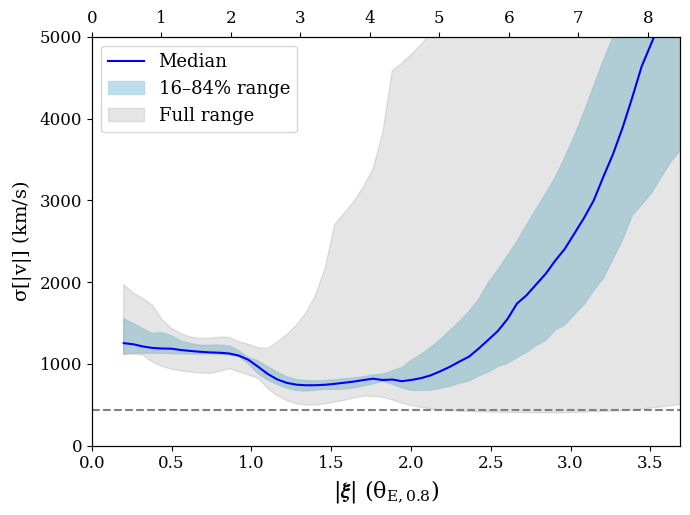

In [18]:
xvels=np.array(uncert_full[:,:,4])
yvels=np.array(uncert_full[:,:,5])
vels=np.array(xvels**2+yvels**2)**(.5)
p16 = (np.array(np.percentile(vels, 16, axis=1), dtype=float))
p84 =  (np.array(np.percentile(vels, 84, axis=1), dtype=float))
p5 = (np.array(np.percentile(vels, 0, axis=1), dtype=float))
p95 =  (np.array(np.percentile(vels, 100, axis=1), dtype=float))

p50=(np.array(np.percentile(vels, 50, axis=1), dtype=float))
fig,ax = plt.subplots(figsize=(7,5.25))
ylim=5000


ax.plot(impact_params / theta_E_8, p50 , color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')
ax.fill_between(impact_params / theta_E_8, p5, p95,  alpha=0.2, label='Full range', color='grey')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
#ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8*rad_to_arcsec)

ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top.tick_params(axis='both', which='major', labelsize=12)
ax.tick_params(axis='both', which='major', labelsize=12)

ax.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\theta_{E, 0.8}$)', fontsize=16)
ax.set_ylabel(r"$\sigma [|v|]$ (km/s)", fontsize=14)
#plt.xlim(0.4, 2.5)
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

plt.savefig('Figures/vel_traj_04.pdf', bbox_inches='tight')


In [19]:
xvels=np.array(uncert_full[:,:,4])
yvels=np.array(uncert_full[:,:,5])
vels=np.array(xvels**2+yvels**2)**(.5)
p50=(np.array(np.percentile(vels, 50, axis=1), dtype=float))

vel_true=np.sqrt(bulk_vel**2+vel_disp**2)

In [22]:
vel_true/(p50)*np.sqrt(5)

array([0.78054734, 0.78932456, 0.80701265, 0.81907761, 0.82393765,
       0.8253752 , 0.83705859, 0.84522328, 0.85252534, 0.85829463,
       0.86118862, 0.8680255 , 0.88866018, 0.931488  , 1.01285795,
       1.11426799, 1.20745754, 1.27397595, 1.31176847, 1.32485537,
       1.32361497, 1.31416265, 1.29394406, 1.27115331, 1.24827226,
       1.21917483, 1.19458439, 1.21894643, 1.20977993, 1.24072496,
       1.21759161, 1.18483341, 1.13850084, 1.07638237, 1.01522953,
       0.95178767, 0.89882572, 0.82488202, 0.75697688, 0.69863031,
       0.63291714, 0.56350963, 0.53224   , 0.496706  , 0.46566161,
       0.43243035, 0.40656208, 0.37703781, 0.35142673, 0.32660462,
       0.29800067, 0.27498668, 0.25212239, 0.23040585, 0.21117378,
       0.1991563 , 0.18845138, 0.17984641, 0.17072666, 0.1622305 ])

In [ ]:
x*

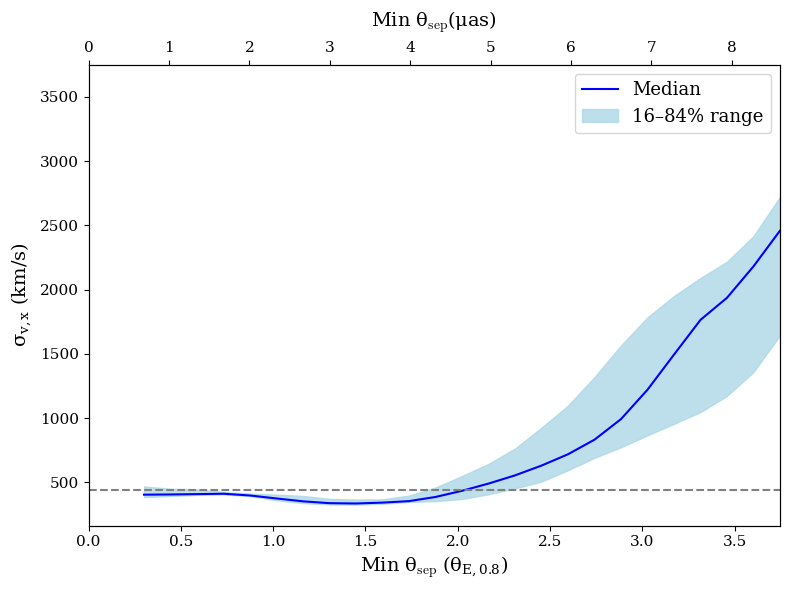

In [52]:
p16 = np.array(np.percentile(uncert_full[:,:,4], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,4], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6)) #actual here has mean around 400 km/s and std 207.2 km/s
ylim=5.1

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,4], 50, axis=1),color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{v, x}$ (km/s)", fontsize=14)
#plt.xlim(0.4, 2.5)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

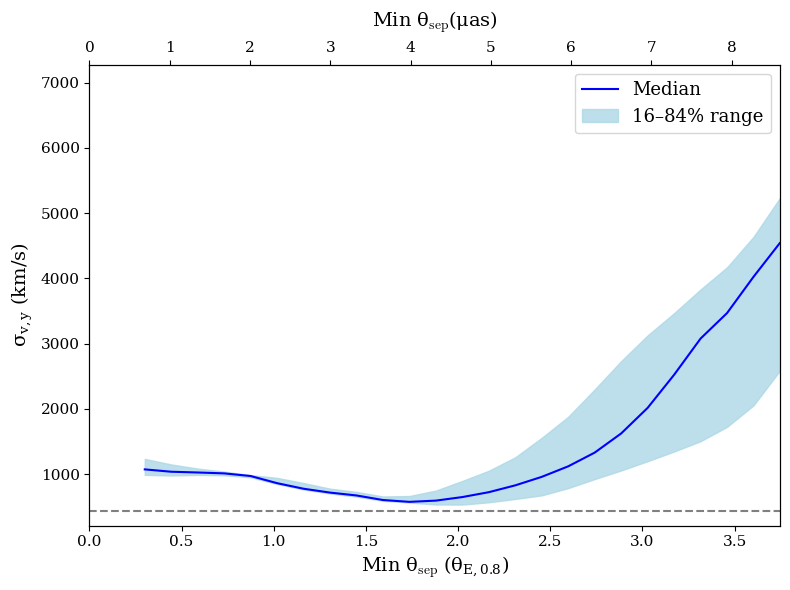

In [53]:
# mean 0 and std 181.4 km/s
p16 = np.array(np.percentile(uncert_full[:,:,5], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,5], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6)) 
ylim=3.7

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,5], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')
ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{v, y}$ (km/s)", fontsize=14)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

In [ ]:
# 2/tau = 4 so we would expect a bit worse here 

### Probabilities

In [8]:
from astropy import units as u
import pandas
def expected_time_to_encounter(stellar_density, v_bulk, v_bulk_err, vel_disp, vel_disp_err, L_min, 
                               B_matrix, redshift, lens_dist, n_samples=100000,seed=None, L_max=None, cutoff=3.6*theta_E_8[0]):
    """
    get expected time for a star to come within L_min of the quasar, given surface density near the quasar and velocity distributions
    inputs:
        stellar_density: surface number density of stars (in 1/rad^2)
        v_bulk: vel of the galaxy in km/s, assuemd to be entirely in the x-direction
        vel_disp: km/s
        L_min: minimum impact distance, ie how close we require our star to be to the quasar
        n_samples: number of samples to estimate the avg transverse speed
    returns:
        t_exp_yr: time until the next close encounter in years
        encounter_rate: inverse of t_exp_yr, num encounters/yr
    """
    
    rng = np.random.default_rng(seed)
    seconds_year=31536000
    km_to_cm = 1e5
    
    # angular => distances in cm
    L_min_phys = L_min * D_l
    if L_max is not None:
        L_max_phys = L_max * D_l
    else:
        L_max_phys = None

    vel_angle = rng.uniform(0, 2*np.pi, size=n_samples)

    # sample bulk velocity and dispersion for each star
    # assume bulk along x, plus Gaussian scatter
    v_bulk_samples = rng.normal(loc=v_bulk, scale=v_bulk_err, size=n_samples)
    vel_disp_samples = rng.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2), size=n_samples)

    # total velocity components
    v_x_kms = v_bulk_samples + vel_disp_samples * np.cos(vel_angle)
    v_y_kms = vel_disp_samples * np.sin(vel_angle)

    # convert to cm/s
    v_rest = np.stack([v_x_kms, v_y_kms], axis=-1) * km_to_cm  # shape (n_samples, 2)

    # apply lensing/angular conversion
    v_ang = np.array([get_velocities(v, B_matrix, redshift, lens_dist) for v in v_rest])
    v_phys = v_ang * lens_dist

    # transverse speed per sample
    v_perp = np.linalg.norm(v_phys, axis=1)  # shape (n_samples,)
    mean_ang_v=(np.mean(np.linalg.norm(v_ang, axis=1)*365.25*24*3600)) #rad/year
    
    # effective width of encounter band
    if L_max_phys is None:
        delta_L = L_min_phys  # encounter within radius L_min
    else:
        delta_L = (L_max_phys - L_min_phys)  # encounter between L_min and L_max

    # per-star area swept per second 
    rate_per_star = 2 * delta_L * v_perp
    encounter_rate = stellar_density * np.mean(rate_per_star)
    t_expected = 1.0 / encounter_rate
    t_exp_yr=t_expected/seconds_year

    #ang_in=cutoff-L_min #rad
    #char_time=2*ang_in/(mean_ang_v)
    #char_time=(2*L_min*rad_to_arcsec)/np.mean(v_perp)/seconds_year
    char_time = 2 * np.sqrt(cutoff**2 - L_min**2) / mean_ang_v # path length inside a circle of radius cutoff is sqrt(cutoff**2-L_min**2)

    
    return t_exp_yr, 1/t_exp_yr, char_time


In [9]:
# kappa values are here: https://arxiv.org/pdf/2303.11987
kappa_star= 0.04 #1.09 #dimensionless, we want this over kappa_crit
kappa_crit=(c**2/(4*np.pi*G))*(D_s/(D_l*D_ls)) # g/cm^2
Sigma_star=kappa_star*kappa_crit
avg_star_mass=.5*u.solMass.to(u.g)
n=(Sigma_star/avg_star_mass) #stars/cm^2
expected_time_to_encounter(n, bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_E_1[0], B_matrix, z_l, D_l, L_max=None)

(np.float64(119.60483998287427),
 np.float64(0.008360865665161928),
 np.float64(37.47995201311994))

In [10]:
impact_params_time=np.array([0.3, 0.730769, 1.161538, 1.592308, 2.023077, 2.453846, 2.884615, 3.315385])
years_bet=[]
years_last=[]
for i in impact_params_time:
    exp, _, char = expected_time_to_encounter(n, bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, i*theta_E_8[0], B_matrix, z_l, D_l, L_max=None)
    years_bet.append(exp)
    years_last.append(char)

In [11]:
df=pandas.DataFrame((np.array((impact_params_time, years_bet, years_last)).T))

In [12]:
df

,0,1,2
0,0.300000,446.816583,39.387338
1,0.730769,183.229655,38.659654
2,1.161538,114.851729,37.232260
3,1.592308,84.055648,35.394808
4,2.023077,66.037382,32.584521
5,2.453846,54.632095,28.923387
6,2.884615,46.329191,23.576070
7,3.315385,40.359201,15.375542


In [ ]:
# this paper: https://arxiv.org/pdf/astro-ph/0511594 
# seems to give very different values for vmin and vmax, so im not sure what thats about